In [1]:
import pandas as pd
import re
import numpy as np

# File processing
from pathlib import Path

# Data viz
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
base_dir = Path("../")
raw_data_dir = base_dir / "raw_data"
parsed_data_dir = base_dir / "parsed_data"
ref_data_dir = Path("../../reference_files/")

# Some references


https://remap.univ-amu.fr/about_atha_page

https://pluto.bio/resources/Learning%20Series/understanding-fraction-and-reads-in-peaks

https://hbctraining.github.io/Intro-to-ChIPseq/lessons/05_peak_calling_macs.html

https://www.frontiersin.org/journals/plant-science/articles/10.3389/fpls.2022.942710/full

# Load

In [3]:
SERIES_ACCESSION = "GSE60141"
sample_metadata_file = parsed_data_dir / f"series_{SERIES_ACCESSION}_sample_metadata.tsv"

In [4]:
sample_df = pd.read_csv(sample_metadata_file, sep="\t")#, index_col=12)
sample_df.set_index("common title", inplace=True)
print(sample_df.shape)
sample_df.head()

(872, 12)


,gene id,dna source,summary,taxon,protein,protein family,protein affinity tag,expression system,subset,replicate,title,accession
common title,,,,,,,,,,,,
MYBrelated_tnt.LHY1_col_a,AT1G01060,col,young leaf,Arabidopsis thaliana,LHY1,MYBrelated,Halo,tnt,motif+TFBS,a,MYBrelated_tnt.LHY1_col_a,GSM1925527
MYBrelated_tnt.LHY1_colamp_a,AT1G01060,colamp,young leaf,Arabidopsis thaliana,LHY1,MYBrelated,Halo,tnt,motif+TFBS,a,MYBrelated_tnt.LHY1_colamp_a,GSM1925526
AP2EREBP_tnt.AT1G01250_col_a,AT1G01250,col,young leaf,Arabidopsis thaliana,AT1G01250,AP2EREBP,Halo,tnt,motif+TFBS,a,AP2EREBP_tnt.AT1G01250_col_a,GSM1925016
AP2EREBP_tnt.AT1G01250_colamp_a,AT1G01250,colamp,young leaf,Arabidopsis thaliana,AT1G01250,AP2EREBP,Halo,tnt,motif,a,AP2EREBP_tnt.AT1G01250_colamp_a,GSM1925015
NAC_tnt.ATAF1_col_a,AT1G01720,col,young leaf,Arabidopsis thaliana,ATAF1,NAC,Halo,tnt,motif+TFBS,a,NAC_tnt.ATAF1_col_a,GSM1925578


In [5]:
sample_df["dna source"].value_counts()

dna source
col       529
colamp    343
Name: count, dtype: int64

In [6]:
sample_df["expression system"].value_counts()

expression system
tnt      870
ecoli      2
Name: count, dtype: int64

## Select Peak files

We select the peak files, using similar filtering steps as in the CisCross article. 

In [7]:
rep_file = raw_data_dir / "ciscross" / "MACS2_chr" / "macs2_summary.tsv"
idr_file = raw_data_dir / "ciscross" / "MACS2_chr" / "macs2_summary_idr.tsv"

number_of_columns = number of peaks (checked)

In [8]:
df_rep_summary_all_reps = pd.read_csv(rep_file, sep="\t")
print(df_rep_summary_all_reps.shape[0])
df_rep_summary_all_reps.head()

932


,geo,srr,dap_id,gene_id,replicate,dna_source,number_of_peaks,frip,mean_length
0,GSM1925002,SRR2926072,ABI3VP1_tnt.AT5G18090_col_a,AT5G18090,a,col,12,0.004,518.58
1,GSM1925003,SRR2926073,ABI3VP1_tnt.AT5G25475_col_a,AT5G25475,a,col,36,0.020,240.19
2,GSM1925004,SRR2926074,ABI3VP1_tnt.AT5G60130_colamp_a,AT5G60130,a,colamp,192,0.096,541.74
3,GSM1925005,SRR2926075,ABI3VP1_tnt.AT5G60130_col_a,AT5G60130,a,col,2221,0.074,130.19
4,GSM1925006,SRR2926076,ABI3VP1_tnt.FUS3_col_a,AT3G26790,a,col,2055,0.181,227.61


In [9]:
df_rep_summary_all_reps[df_rep_summary_all_reps["gene_id"]=="AT3G23210"]

,geo,srr,dap_id,gene_id,replicate,dna_source,number_of_peaks,frip,mean_length
759,GSM1925761,SRR2926831,bHLH_tnt.bHLH34_colamp_a,AT3G23210,a,colamp,190,0.004,401.46
914,GSM1925916,SRR2926986,bHLH_tnt.bHLH34_col_a,AT3G23210,a,col,112,0.008,390.30
915,GSM1925917,SRR2926987,bHLH_tnt.bHLH34_col_b,AT3G23210,b,col,116,0.009,392.59


<Axes: xlabel='frip', ylabel='number_of_peaks'>

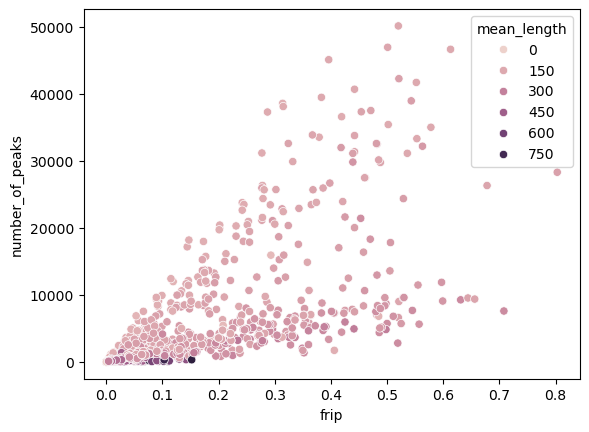

In [10]:
sns.scatterplot(df_rep_summary_all_reps, x="frip", y="number_of_peaks", hue="mean_length")

### FriP filter


From article:
> We filtered out the peak sets with the fraction of reads in peaks (FRIP, Landt et al., 2012) less than 0.01.

From web (https://pluto.bio/resources/Learning%20Series/understanding-fraction-and-reads-in-peaks):
> The fraction of reads in peaks (commonly denoted as FRiP) is a measure of how many of the total reads are found within the peaks. It is calculated as the number of reads in peaks divided by the total number of reads. This value can be used to assess the quality of the data and the specificity of the experiment. A high fraction of reads in peaks indicates that the majority of the reads are located in the regions of interest, and that the experiment has a high signal-to-noise ratio. On the other hand, a low fraction of reads in peaks may indicate that the majority of the reads are located in non-specific regions, and that the experiment has a low specificity.



<Axes: >

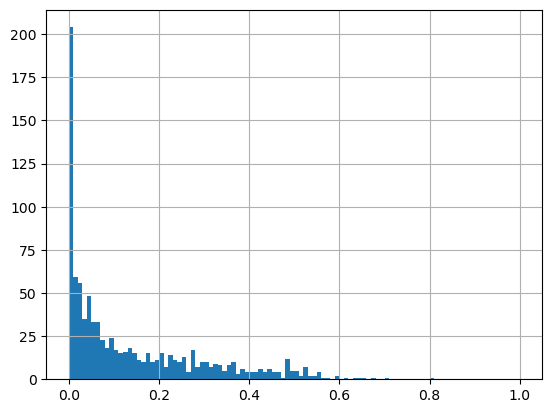

In [11]:
df_rep_summary_all_reps["frip"].hist(bins=np.linspace(0, 1, 101))

In [12]:
df_rep_summary = df_rep_summary_all_reps[df_rep_summary_all_reps["frip"] >= 0.01].copy()
df_rep_summary.shape[0]

728

In [13]:
len(set(df_rep_summary["gene_id"]))

454

### Choosing between IDR or a replicate of an experiment

Irreproducible Discovery Rate (IDR) - measures consistency between replicates in high-throughput experiments, also uses reproducibility in score rankings between peaks in each replicate to determine an optimal cutoff for significance. 

From article:
> If an idr-processed set of peaks contained more than 2000 peaks, or its size at least twice exceeded one for an individual replica with the maximal number of peaks, then we chose an idr-processed set. In other cases, we chose an individual replica with the maximal FRIP value.


Translated to:

- If IDR has > 2000 peaks pick IDR
- If IDR has more than half the number of peaks of the replicate with the most peaks, pick the IDR
- Otherwise, pick the replicate with the best FRiP
- If the FRiP is the same, pick the preplicate with the most peaks

In [14]:
df_idr_summary = pd.read_csv(idr_file, sep="\t")
print(df_idr_summary.shape)
df_idr_summary.head()

(59, 3)


,idr_id,old_ids,number_of_columns
0,AP2EREBP_tnt.At1g22810_col_idr,AP2EREBP_tnt.At1g22810_col_a;AP2EREBP_tnt.At1g...,624
1,AP2EREBP_tnt.At2g33710_col_idr,AP2EREBP_tnt.At2g33710_col_a;AP2EREBP_tnt.At2g...,1055
2,AP2EREBP_tnt.At4g32800_col_idr,AP2EREBP_tnt.At4g32800_col200_a;AP2EREBP_tnt.A...,628
3,AP2EREBP_tnt.ERF105_col_idr,AP2EREBP_tnt.ERF105_col_a;AP2EREBP_tnt.ERF105_...,93
4,AP2EREBP_tnt.ERF15_col_idr,AP2EREBP_tnt.ERF15_col100_a;AP2EREBP_tnt.ERF15...,1085


In [15]:
file_to_use = {}
idrs_to_use = []
for _, row in df_idr_summary.iterrows():

    print(row['idr_id'])
    
    use_idr = False
    
    reps = df_rep_summary[df_rep_summary['dap_id'].isin(row['old_ids'].split(";"))].sort_values("number_of_peaks", ascending=False)
    # print(reps)
    if reps.shape[0] == 0:
        print("\tno reps with Frip")
        continue
    
    if row['number_of_columns'] > 2000:
        use_idr = True
    
    else:

        best_rep = reps['number_of_peaks'].max()
        if not(row['number_of_columns'] < best_rep/2):
            use_idr = True
    
    if use_idr:
        idrs_to_use.append(row['idr_id'])
        for rep in reps['dap_id']:
            file_to_use[rep] = row['idr_id']
    
    else:
        print(row['idr_id'], row['old_ids'], row['number_of_columns'])
        # choose the replicate
        for rep in reps['dap_id']:
            rep_row = reps[reps["frip"] == reps["frip"].max()]
            file_to_use[rep] = rep_row['dap_id'].iloc[0]        

AP2EREBP_tnt.At1g22810_col_idr
AP2EREBP_tnt.At1g22810_col_idr AP2EREBP_tnt.At1g22810_col_a;AP2EREBP_tnt.At1g22810_col_b 624
AP2EREBP_tnt.At2g33710_col_idr
AP2EREBP_tnt.At2g33710_col_idr AP2EREBP_tnt.At2g33710_col_a;AP2EREBP_tnt.At2g33710_col_b 1055
AP2EREBP_tnt.At4g32800_col_idr
AP2EREBP_tnt.At4g32800_col_idr AP2EREBP_tnt.At4g32800_col200_a;AP2EREBP_tnt.At4g32800_col_b 628
AP2EREBP_tnt.ERF105_col_idr
AP2EREBP_tnt.ERF105_col_idr AP2EREBP_tnt.ERF105_col_a;AP2EREBP_tnt.ERF105_col_b 93
AP2EREBP_tnt.ERF15_col_idr
AP2EREBP_tnt.ERF15_col_idr AP2EREBP_tnt.ERF15_col100_a;AP2EREBP_tnt.ERF15_col_b 1085
AP2EREBP_tnt.ERF6_col_idr
	no reps with Frip
C2H2_tnt.At5g66730_col_idr
C2H2_tnt.IDD5_col_idr
	no reps with Frip
C2H2_tnt.STZ_col_idr
C2H2_tnt.STZ_col_idr C2H2_tnt.STZ_col100_a;C2H2_tnt.STZ_col_b 1317
CPP_tnt.SOL1_col_idr
G2like_tnt.At1g25550_col_idr
G2like_tnt.At1g25550_col_idr G2like_tnt.At1g25550_col100_a;G2like_tnt.At1g25550_col_b 1882
G2like_tnt.At1g68670_col_idr
G2like_tnt.At1g68670_col_idr G

In [16]:
file_replaced_with_idr = []
flunked = 0

for common_title, row in sample_df.iterrows():
    print(common_title)
    files = []
    number_peaks = None
    frip = []
    for rep in row['title'].split(","):

        print("\t", rep)        
        file_name = None
        
        if rep in file_to_use:
            if file_to_use[rep] in idrs_to_use:
                file_name = f"../raw_data/ciscross/MACS2_chr/macs2_idr/{file_to_use[rep]}.bed"
                file_replaced_with_idr.append(common_title)
                
                number_peaks = df_idr_summary.loc[df_idr_summary["idr_id"] == file_to_use[rep], "number_of_columns"].iloc[0]
                sample_df.loc[common_title, "IDR"] = True

                for sub_rep in df_idr_summary.set_index("idr_id").loc[file_to_use[rep]]['old_ids'].split(";"):
                    frip.append(df_rep_summary.set_index("dap_id").loc[sub_rep, "frip"])

            else:
                file_name = f"../raw_data/ciscross/MACS2_chr/macs2_chr/{file_to_use[rep]}.bed"
                
                number_peaks = df_rep_summary.loc[df_rep_summary["dap_id"] == file_to_use[rep], "number_of_peaks"].iloc[0]
                frip.append(df_rep_summary.loc[df_rep_summary["dap_id"] == file_to_use[rep], "frip"].iloc[0])
           
        else:
            if rep in df_rep_summary["dap_id"].values:       
                rep_row = df_rep_summary[df_rep_summary["dap_id"] == rep].iloc[0]
                file_name = f"../raw_data/ciscross/MACS2_chr/macs2_chr/{rep_row['dap_id']}.bed"

                number_peaks = rep_row["number_of_peaks"]
                frip.append(rep_row["frip"])

            else:
                print("\t\t", "not in replicates table!", "failed frip:", (df_rep_summary_all_reps.loc[df_rep_summary_all_reps["dap_id"] == rep, "frip"] < 0.01).values)
        
        if file_name:
            if not Path(file_name).exists():
                print(file_name, "does not exist")
            else:
                files.append(file_name)
    
    print()
    if len(set(files)) == 1:
        sample_df.loc[common_title, "file"] = files[0]
        sample_df.loc[common_title, "number_of_peaks"] = number_peaks
        sample_df.loc[common_title, "frip"] = max(frip)

        print("\t", number_peaks, frip)
    
    else:
        flunked += 1
        if len(set(files)) > 1:
            print(common_title, "issue", files)
            break

        else:
            # print(common_title, "none passed")
            continue
    


MYBrelated_tnt.LHY1_col_a
	 MYBrelated_tnt.LHY1_col_a

	 7970 [0.353]
MYBrelated_tnt.LHY1_colamp_a
	 MYBrelated_tnt.LHY1_colamp_a

	 23939 [0.421]
AP2EREBP_tnt.AT1G01250_col_a
	 AP2EREBP_tnt.AT1G01250_col_a

	 302 [0.034]
AP2EREBP_tnt.AT1G01250_colamp_a
	 AP2EREBP_tnt.AT1G01250_colamp_a
		 not in replicates table! failed frip: [ True]

NAC_tnt.ATAF1_col_a
	 NAC_tnt.ATAF1_col_a

	 984 [0.037]
NAC_tnt.ATAF1_colamp_a
	 NAC_tnt.ATAF1_colamp_a

	 131 [0.056]
NAC_tnt.ANAC004_col_a
	 NAC_tnt.ANAC004_col_a

	 7279 [0.423]
NAC_tnt.ANAC004_colamp_a
	 NAC_tnt.ANAC004_colamp_a

	 9666 [0.177]
NAC_tnt.ANAC005_col_a
	 NAC_tnt.ANAC005_col_a

	 5004 [0.134]
AP2EREBP_tnt.ERF10_col_a
	 AP2EREBP_tnt.ERF10_col_a
		 not in replicates table! failed frip: [ True]

AP2EREBP_tnt.ERF10_colamp_a
	 AP2EREBP_tnt.ERF10_colamp_a

	 807 [0.013]
C2H2_tnt.MGP_col_a
	 C2H2_tnt.MGP_col_a
		 not in replicates table! failed frip: [ True]

C2H2_tnt.MGP_colamp_a
	 C2H2_tnt.MGP_colamp_a

	 3923 [0.044]
ARID_tnt.AT1G04880_col_

In [17]:
sample_df = sample_df[~sample_df["file"].isna()]

### Filtering by number of peaks:

> Finally, we took in further analysis sets containing at least 200 peaks. 

<Axes: xlabel='number_of_peaks', ylabel='Count'>

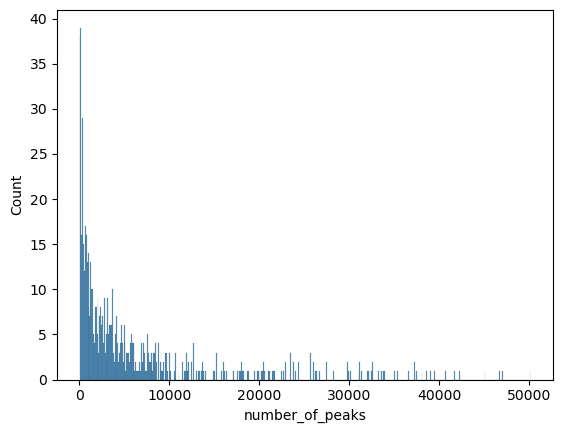

In [18]:
sns.histplot(sample_df, x="number_of_peaks", binwidth=100)

<Axes: xlabel='subset', ylabel='number_of_peaks'>

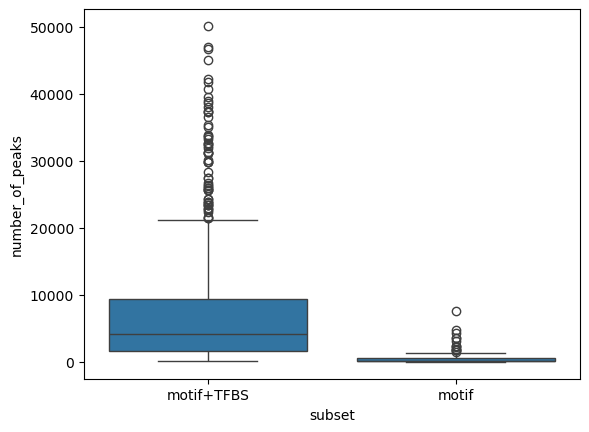

In [19]:
sns.boxplot(sample_df, y="number_of_peaks", x="subset")

In [20]:
sample_df.shape

(681, 16)

### Only use "motif+TFBS" data subset

(Makes no difference to do this before or after rest of filtering)

In [22]:
# sample_df = sample_df[sample_df["subset"] == "motif+TFBS"]

In [23]:
sample_df.shape

(681, 16)

## Checks to compare files after filtering to CisCross what we're missing...

Here, CisCross do not subset to "motif+TFBS", so we'll be missing a few files

In [24]:
df = pd.read_excel("../literature/Data Sheet 1_edited.xlsx", sheet_name="Supplementary Table S3_1")

In [25]:
df = df[df["CisCross-MACS2"]>=200]

In [26]:
# This checks we picked the same IDR
for x, row in sample_df.iterrows():
    if (  len(row["accession"].split(',')) > 1 ) and (  row["IDR"] is not True  ):
        if row['file']is np.nan:
            # print("---", x, row["gene id"], row["number_of_peaks"])
            continue
        else:
            s = df[df["TAIR ID"] == row["gene id"]]
            if not (s["CisCross-MACS2"] == row["number_of_peaks"]).sum() ==1:

                print(x, row["gene id"], row["number_of_peaks"])
                display(df[df["TAIR ID"] == row["gene id"]])

                display(df_rep_summary_all_reps[df_rep_summary_all_reps['dap_id'].isin(sample_df.loc[x]["title"].split(","))])
                display(df_idr_summary[df_idr_summary["idr_id"].str.startswith(x)])



Homeobox_tnt.EDT1 AT1G73360 48.0


,TF name,TAIR ID,family,CisCross-MACS2,CisCross GEM,GEM,Unnamed: 6


,geo,srr,dap_id,gene_id,replicate,dna_source,number_of_peaks,frip,mean_length
842,GSM1925844,SRR2926914,Homeobox_tnt.EDT1_100ng20cy_b,AT1G73360,b,col,48,0.025,379.17
843,GSM1925845,SRR2926915,Homeobox_tnt.EDT1_col200_a,AT1G73360,a,col,23,0.002,378.13


,idr_id,old_ids,number_of_columns
14,Homeobox_tnt.EDT1_col200_idr,Homeobox_tnt.EDT1_100ng20cy_b;Homeobox_tnt.EDT...,10


In [27]:
set(df["TAIR ID"]) - set(sample_df["gene id"])

{'AT3G23210', 'AT4G17785'}

In [30]:
# This is due to skipping the number of peaks filter
set(sample_df["gene id"]) - set(df["TAIR ID"])

{'AT1G06070',
 'AT1G09030',
 'AT1G10120',
 'AT1G13300',
 'AT1G13450',
 'AT1G18960',
 'AT1G32240',
 'AT1G32510',
 'AT1G46264',
 'AT1G47870',
 'AT1G60920',
 'AT1G63040',
 'AT1G65620',
 'AT1G69180',
 'AT1G72050',
 'AT1G73360',
 'AT1G74370',
 'AT2G21900',
 'AT2G31460',
 'AT2G40340',
 'AT2G41835',
 'AT2G46400',
 'AT3G03660',
 'AT3G06740',
 'AT3G12820',
 'AT3G12910',
 'AT3G13040',
 'AT3G20840',
 'AT3G23690',
 'AT3G30210',
 'AT3G30530',
 'AT3G57230',
 'AT3G58630',
 'AT3G61120',
 'AT4G04450',
 'AT4G11080',
 'AT4G12670',
 'AT4G14410',
 'AT4G17460',
 'AT4G28140',
 'AT4G30980',
 'AT5G07100',
 'AT5G08070',
 'AT5G25475',
 'AT5G38860',
 'AT5G42520',
 'AT5G44160',
 'AT5G52170',
 'AT5G62165',
 'AT5G65130'}

## Load and merge DAPseq peak files

In [31]:
narrowpeak_colums = [ #https://genome.ucsc.edu/FAQ/FAQformat.html#format12
    "chrom",       #Name of the chromosome (or contig, scaffold, etc.).
    "chromStart",  #The starting position of the feature in the chromosome or scaffold. The first base in a chromosome is numbered 0.
    "chromEnd",    #The ending position of the feature in the chromosome or scaffold. The chromEnd base is not included in the display of the feature. For example, the first 100 bases of a chromosome are defined as chromStart=0, chromEnd=100, and span the bases numbered 0-99.
    "name",        #Name given to a region (preferably unique). Use "." if no name is assigned.
    "score",       #Indicates how dark the peak will be displayed in the browser (0-1000). If all scores were "'0"' when the data were submitted to the DCC, the DCC assigned scores 1-1000 based on signal value. Ideally the average signalValue per base spread is between 100-1000.
    "strand",      #+/- to denote strand or orientation (whenever applicable). Use "." if no orientation is assigned.
    "signalValue", #Measurement of overall (usually, average) enrichment for the region.
    "pValue",      #Measurement of statistical significance (-log10). Use -1 if no pValue is assigned.
    "qValue",      #Measurement of statistical significance using false discovery rate (-log10). Use -1 if no qValue is assigned.
    "peak",        #Point-source called for this peak; 0-based offset from chromStart. Use -1 if no point-source called.
]

idr_columns = [
"chrom", # string Name of the chromosome for common peaks
"chromStart", # int The starting position of the feature in the chromosome or scaffold for common peaks, shifted based on offset. The first base in a chromosome is numbered 0.
"chromEnd", # int The ending position of the feature in the chromosome or scaffold for common peaks. The chromEnd base is not included in the display of the feature.
"name", # string Name given to a region (preferably unique) for common peaks. Use '.' if no name is assigned.
"score", # int Contains the scaled IDR value, min(int(log2(-125IDR), 1000). e.g. peaks with an IDR of 0 have a score of 1000, idr 0.05 have a score of int(-125log2(0.05)) = 540, and idr 1.0 has a score of 0.
"strand", # [+-.] Use '.' if no strand is assigned.
"signalValue", # float Measurement of enrichment for the region for merged peaks. When a peak list is provided this is the value from the peak list.
"pValue", # float Merged peak p-value. When a peak list is provided this is the value from the peak list.
"qValue", # float Merged peak q-value. When a peak list is provided this is the value from the peak list.
"peak", # summit int Merged peak summit

"localIDR", # float -log10(Local IDR value)

"globalIDR" #float -log10(Global IDR value)

# rep1_chromStart int
# The starting position of the feature in the chromosome or scaffold for common replicate 1 peaks, shifted based on offset. The first base in a chromosome is numbered 0.

# rep1_chromEnd int
# The ending position of the feature in the chromosome or scaffold for common replicate 1 peaks. The chromEnd base is not included in the display of the feature.

# rep1_signalValue float
# Signal measure from replicate 1. Note that this is determined by the --rank option. e.g. if --rank is set to signal.value, this corresponds to the 7th column of the narrowPeak, whereas if it is set to p.value it corresponds to the 8th column.

# rep1_summit int
# The summit of this peak in replicate 1.

# [rep 2 data]

# ...

# [rep N data]
]

In [32]:
sample_df

,gene id,dna source,summary,taxon,protein,protein family,protein affinity tag,expression system,subset,replicate,title,accession,file,number_of_peaks,frip,IDR
common title,,,,,,,,,,,,,,,,
MYBrelated_tnt.LHY1_col_a,AT1G01060,col,young leaf,Arabidopsis thaliana,LHY1,MYBrelated,Halo,tnt,motif+TFBS,a,MYBrelated_tnt.LHY1_col_a,GSM1925527,../raw_data/ciscross/MACS2_chr/macs2_chr/MYBre...,7970.0,0.353,NaN
MYBrelated_tnt.LHY1_colamp_a,AT1G01060,colamp,young leaf,Arabidopsis thaliana,LHY1,MYBrelated,Halo,tnt,motif+TFBS,a,MYBrelated_tnt.LHY1_colamp_a,GSM1925526,../raw_data/ciscross/MACS2_chr/macs2_chr/MYBre...,23939.0,0.421,NaN
AP2EREBP_tnt.AT1G01250_col_a,AT1G01250,col,young leaf,Arabidopsis thaliana,AT1G01250,AP2EREBP,Halo,tnt,motif+TFBS,a,AP2EREBP_tnt.AT1G01250_col_a,GSM1925016,../raw_data/ciscross/MACS2_chr/macs2_chr/AP2ER...,302.0,0.034,NaN
NAC_tnt.ATAF1_col_a,AT1G01720,col,young leaf,Arabidopsis thaliana,ATAF1,NAC,Halo,tnt,motif+TFBS,a,NAC_tnt.ATAF1_col_a,GSM1925578,../raw_data/ciscross/MACS2_chr/macs2_chr/NAC_t...,984.0,0.037,NaN
NAC_tnt.ATAF1_colamp_a,AT1G01720,colamp,young leaf,Arabidopsis thaliana,ATAF1,NAC,Halo,tnt,motif,a,NAC_tnt.ATAF1_colamp_a,GSM1925577,../raw_data/ciscross/MACS2_chr/macs2_chr/NAC_t...,131.0,0.056,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AP2EREBP_tnt.DEAR2_colamp_a,AT5G67190,colamp,young leaf,Arabidopsis thaliana,DEAR2,AP2EREBP,Halo,tnt,motif+TFBS,a,AP2EREBP_tnt.DEAR2_colamp_a,GSM1925071,../raw_data/ciscross/MACS2_chr/macs2_chr/AP2ER...,25959.0,0.386,NaN
MYB_tnt.MYB44_col,AT5G67300,col,young leaf,Arabidopsis thaliana,MYB44,MYB,Halo,tnt,motif+TFBS,"a,b","MYB_tnt.MYB44_col100_a,MYB_tnt.MYB44_col_b","GSM1925848,GSM1925849",../raw_data/ciscross/MACS2_chr/macs2_chr/MYB_t...,5395.0,0.372,NaN
MYB_tnt.MYB44_colamp_a,AT5G67300,colamp,young leaf,Arabidopsis thaliana,MYB44,MYB,Halo,tnt,motif,a,MYB_tnt.MYB44_colamp_a,GSM1925449,../raw_data/ciscross/MACS2_chr/macs2_chr/MYB_t...,513.0,0.014,NaN


In [33]:
p001 = -np.log10(0.01)
p005 = -np.log10(0.05)
print(p001, p005)

2.0 1.3010299956639813


In [36]:
dapseq_dfs = []
for t, row in sample_df.iterrows():
    
    f = row["file"]
    if t in file_replaced_with_idr:
        df = pd.read_csv(f, sep='\t', header=None, names=idr_columns, usecols=[0,1,2,3,4,5,6,7,8,9,10,11])
        df["qValue"] = df["localIDR"]
        df = df[df["qValue"]>p001]
        df = df[narrowpeak_colums]
        # t = f"{t}-IDR-{row['dna source']}"
    else:
        df = pd.read_csv(f, sep='\t', header=None, names=narrowpeak_colums)
        df = df[df["qValue"]>p001]
        # t = f"{t}-{row['replicate']}-{row['dna source']}"
    
    df['common title'] = t
    df["dna source"] = row['dna source']
    dapseq_dfs.append(df)


In [37]:
print(len(dapseq_dfs))

681


In [38]:
dapseq_df = pd.concat(dapseq_dfs)
dapseq_df.shape

(4370250, 12)

In [39]:
dapseq_df.head()

,chrom,chromStart,chromEnd,name,score,strand,signalValue,pValue,qValue,peak,common title,dna source
0,chr1,141,295,SRR2926597.filtered.BAM_peak_1,78,.,6.58138,10.19656,7.88710,66,MYBrelated_tnt.LHY1_col_a,col
1,chr1,8025,8247,SRR2926597.filtered.BAM_peak_2,204,.,13.32415,23.72455,20.49854,113,MYBrelated_tnt.LHY1_col_a,col
2,chr1,16285,16428,SRR2926597.filtered.BAM_peak_3,39,.,4.69202,5.94877,3.94847,56,MYBrelated_tnt.LHY1_col_a,col
3,chr1,44590,44928,SRR2926597.filtered.BAM_peak_4,39,.,4.57394,5.94877,3.94847,63,MYBrelated_tnt.LHY1_col_a,col
4,chr1,66684,66995,SRR2926597.filtered.BAM_peak_5,106,.,6.78865,13.19086,10.66210,165,MYBrelated_tnt.LHY1_col_a,col


In [40]:
def print_stats(X, decimals=2):
    stats = [
        ("min", X.min()),
        ("max", X.max()),
        ("mean", X.mean()),
        ("median:", X.median()),
        
        ("lower quantile (25) ", X.quantile(0.25)),
        ("upper quantile (75) ", X.quantile(0.75)),
        ("number", X.shape[0])
    ]

    display(pd.DataFrame(stats, columns=["stat", "value"]).round(decimals).style.format({"value":"{:,}"}))

In [41]:
print_stats(dapseq_df["score"])

,stat,value
0,min,20.0
1,max,"99,645.0"
2,mean,201.73
3,median:,107.0
4,lower quantile (25),63.0
5,upper quantile (75),221.0
6,number,"4,370,250.0"


In [42]:
print_stats(dapseq_df["qValue"])

,stat,value
0,min,2.0
1,max,"9,964.59"
2,mean,19.43
3,median:,10.53
4,lower quantile (25),6.19
5,upper quantile (75),21.45
6,number,"4,370,250.0"


In [43]:
print_stats(dapseq_df["signalValue"])

,stat,value
0,min,1.24
1,max,366.83
2,mean,8.96
3,median:,6.66
4,lower quantile (25),4.98
5,upper quantile (75),10.16
6,number,"4,370,250.0"


## To BED format

In [44]:
from pybedtools import BedTool
from pybedtools.helpers import cleanup as bedtools_cleanup

In [45]:
bedtools_cleanup()

In [46]:
from pybedtools.helpers import set_tempdir
bedtools_tmp = raw_data_dir / "bedtools_tmp"
bedtools_tmp.mkdir(parents=True, exist_ok=True)

set_tempdir(bedtools_tmp)

In [47]:
# https://github.com/daler/pybedtools/issues/252
def is_valid_bedtools(a):
    '''Does not work for BedTool from iterable'''
    try:
        ft = a.file_type
        if ft == 'empty':
            print("empty file!")
        else:
            print(f'input is {ft} - OK!')
    except IndexError:
        print('bad input!')
    

## Dapseq bed

In [48]:
# peak with start < 0
dapseq_df.loc[dapseq_df["chromStart"] < 0, 'chromStart'] = 0

In [49]:
dapseq_df.loc[:,"chrom"] = dapseq_df["chrom"].str.capitalize()

In [50]:
dapseq_df.loc[:, 'name'] = dapseq_df.apply(lambda x: f"{x['chrom'][3:]}:{x['chromStart']}-{x['common title']}", axis=1)

In [51]:
for subset in ["col", "colamp"]:
    subdf = dapseq_df[dapseq_df["dna source"] == subset]
    dapseq_bed = BedTool.from_dataframe(subdf[["chrom", "chromStart", "chromEnd", "name"]])
    dapseq_bed = dapseq_bed.sort()
    is_valid_bedtools(dapseq_bed)
    dapseq_bed.saveas( parsed_data_dir / f"{subset}_merged_filtered_dapseq_peaks.bed")
    subdf.to_csv( parsed_data_dir / f"{subset}_merged_filtered_dapseq_peaks.tsv", sep="\t")

    print(subset, subdf.shape[0])
    print()

input is bed - OK!
col 1024013

input is bed - OK!
colamp 3346237



In [48]:
for subset in ["col", "colamp"]:
    subdf = dapseq_df[dapseq_df["dna source"] == subset]
    dapseq_bed = BedTool.from_dataframe(subdf[["chrom", "chromStart", "chromEnd", "name"]])
    dapseq_bed = dapseq_bed.sort()
    is_valid_bedtools(dapseq_bed)
    dapseq_bed.saveas( parsed_data_dir / f"{subset}_merged_filtered_dapseq_peaks.bed")
    subdf.to_csv( parsed_data_dir / f"{subset}_merged_filtered_dapseq_peaks.tsv", sep="\t")

    print(subset, subdf.shape[0])
    print()

input is bed - OK!
col 1017976
input is bed - OK!
colamp 3277606


In [53]:
peakset_metadata_file = parsed_data_dir / f"series_{SERIES_ACCESSION}_peakset_metadata.tsv"
sample_df.to_csv(peakset_metadata_file)

In [ ]:
# END